# Generic logistic regression model

Trains a logistic regression model on any dataset with categorical variables (3-10 categories) without knowing the specific variable names.

Target and ID columns are detected from candidate name lists (`var1`, `event_oneyear`, `target`, `outcome`, `y`, `label` for the target; `trr_id_code`, `id`, `patient_id`, `subject_id` for the ID), or named explicitly in the config. One-hot encoded categoricals are read as groups, with their reference columns chosen during preprocessing and reported below. Hyperparameters are set in the configuration cell.


## Setup and imports


In [1]:
%load_ext autoreload
%autoreload 2

# Set CPU fallback for MPS (Apple Silicon)
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
print("PYTORCH_ENABLE_MPS_FALLBACK =", os.environ.get('PYTORCH_ENABLE_MPS_FALLBACK'))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import logging
import torch.nn as nn
import torch.optim as optim
from pathlib import Path

from datetime import datetime
from prism.config import INTERIM_DATA_DIR, MODELS_DIR, PROCESSED_DATA_DIR, PROJ_ROOT
from prism.config import DATASET_PREFIX, CONFIG_NAME
from prism.logging_config import setup_logging
from prism.config_loader import (
    load_config_if_exists,
    detect_target_and_id_columns,
    DEFAULT_TARGET_CANDIDATES,
    DEFAULT_ID_CANDIDATES,
)

# =============================================================================
# DATASET CHECK - Ensure .env is configured
# =============================================================================
if DATASET_PREFIX is None:
    print("=" * 70)
    print("ERROR: No dataset configured!")
    print("=" * 70)
    print("\nPlease configure your dataset in the .env file:")
    print("  1. Copy .env.example to .env")
    print("  2. Set PRISM_CONFIG=your_config (loads example_notebooks/config/your_config.yaml)")
    print("     OR set PRISM_DATASET=your_dataset (quick mode, no YAML needed)")
    print("\nExample .env contents:")
    print("  PRISM_CONFIG=htx_example")
    print("=" * 70)
    raise ValueError("DATASET_PREFIX is None - configure .env file")

print(f"Dataset: {DATASET_PREFIX}")
if CONFIG_NAME:
    print(f"Config: {CONFIG_NAME}.yaml")

from prism.device_tools import get_device, get_num_cpu_workers
from prism.preprocessing import PRiSMScaler, detect_reference_columns
from prism.data_utilities import save_split_datasets
from prism.metrics import evaluate_model_performance
from prism.logreg import LogisticRegression

PYTORCH_ENABLE_MPS_FALLBACK = 1


2026-02-04 13:01:37.811 | INFO     | prism.config:<module>:15 - PROJ_ROOT path is: C:\Users\user\PRiSM


2026-02-04 13:01:37.837 | INFO     | prism.config:<module>:71 - Config mode: CONFIG_NAME=credit-g_full, DATASET_PREFIX=credit-g


C:\Users\user\PRiSM\venv_prism\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: credit-g
Config: credit-g_full.yaml


## Configuration


In [2]:
# ============================================================================
# CONFIGURATION
# ============================================================================
model_name = 'logreg'
DATA_PREFIX = DATASET_PREFIX  # from config.py

# Random seed for reproducibility
random_seed = 257

# ============================================================================
# TARGET AND ID VARIABLE CONFIGURATION (MANUAL DEFAULTS)
# ============================================================================
# These defaults are imported from prism.config_loader but can be overridden here.
# To customize, uncomment and modify the lines below:
# TARGET_CANDIDATES = ['my_target', 'outcome', 'label']
# ID_CANDIDATES = ['my_id', 'patient_id']
TARGET_CANDIDATES = list(DEFAULT_TARGET_CANDIDATES)  # Copy to allow modification
ID_CANDIDATES = list(DEFAULT_ID_CANDIDATES)  # Copy to allow modification

# ============================================================================
# LOAD CONFIG FILE (OVERRIDES MANUAL SETTINGS ABOVE)
# ============================================================================
# Use CONFIG_NAME if set (from .env PRISM_CONFIG), otherwise try DATA_PREFIX
config_to_load = CONFIG_NAME if CONFIG_NAME else DATA_PREFIX
config = load_config_if_exists(config_to_load)

if config:
    print(f"Config file found: {config_to_load}.yaml")
    if 'random_seed' in config:
        random_seed = config['random_seed']
        print(f"   [ok] random_seed: {random_seed}")
    if 'target_candidates' in config:
        TARGET_CANDIDATES = config['target_candidates']
        print(f"   [ok] target_candidates: {TARGET_CANDIDATES}")
    if 'id_candidates' in config:
        ID_CANDIDATES = config['id_candidates']
        print(f"   [ok] id_candidates: {ID_CANDIDATES}")
else:
    print("No config file found - using manual settings above")
    print("Edit the settings in the cells above if needed.")

# Apply random seed
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_seed)
    torch.cuda.manual_seed_all(random_seed)

# Device: 'device' in the YAML config or the PRISM_DEVICE env var overrides
# auto-detection ('auto', 'cpu', 'cuda', 'mps'); default is the best available
device = get_device(config.get('device') if config else None)
print(f"Using device: {device}")

# Check the data prefix that will be used to load train, test, and validation cohorts
print(f"DATA_PREFIX = '{DATA_PREFIX}'")
print(f"Will load data files from {INTERIM_DATA_DIR}:")

# Define filename variables
train_filename = f'{DATA_PREFIX}_train.csv'
test_filename = f'{DATA_PREFIX}_test.csv'
val_filename = f'{DATA_PREFIX}_val.csv'

print(f"  - {train_filename}")
print(f"  - {test_filename}") 
print(f"  - {val_filename}")

model_identifier = f"{DATA_PREFIX}_{model_name}"
print(f"Model identifier: {model_identifier}")

# Set up logging (use logging.DEBUG for more detailed logs, logging.INFO for less detailed logs)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
setup_logging(
    file_log_level=logging.INFO,
    log_file=f'model_{DATA_PREFIX}_{model_identifier}_{timestamp}.log',
    console_output=True,
    root_log_level=logging.WARNING,
)

Config file found: credit-g_full.yaml
   [ok] random_seed: 257
Using device: cuda
DATA_PREFIX = 'credit-g'
Will load data files from C:\Users\user\PRiSM\data\interim:
  - credit-g_train.csv
  - credit-g_test.csv
  - credit-g_val.csv
Model identifier: credit-g_logreg
[2026-02-04 13:01:39] INFO [logging_config.py:73] - Logging setup complete. Logs will be saved to: C:\Users\user\PRiSM\logs\model_credit-g_credit-g_logreg_20260204_130139.log (console output enabled)


## Data loading and variable detection


In [3]:
# Load data
print("Loading data...")
# Skip comment lines that start with '#' to avoid header issues
data_train = pd.read_csv(INTERIM_DATA_DIR.joinpath(train_filename), comment='#')
data_test = pd.read_csv(INTERIM_DATA_DIR.joinpath(test_filename), comment='#')
data_val = pd.read_csv(INTERIM_DATA_DIR.joinpath(val_filename), comment='#')

print(f"Training data shape: {data_train.shape}")
print(f"Test data shape: {data_test.shape}")
print(f"Validation data shape: {data_val.shape}")

Loading data...
Training data shape: (600, 44)
Test data shape: (200, 44)
Validation data shape: (200, 44)


In [4]:
# Detect target and ID columns using the centralized function from prism.config_loader
target_column, id_column = detect_target_and_id_columns(
    data_train,
    target_candidates=TARGET_CANDIDATES,
    id_candidates=ID_CANDIDATES,
)

# Fallback detection if automatic detection fails
if target_column is None:
    print("\n" + "=" * 50)
    print("FALLBACK TARGET DETECTION")
    print("=" * 50)

    # Try to find binary columns that could be targets
    binary_cols = []
    for col in data_train.columns:
        unique_vals = sorted(data_train[col].dropna().unique())
        if len(unique_vals) == 2 and set(unique_vals) == {0, 1}:
            binary_cols.append(col)

    if binary_cols:
        target_column = binary_cols[0]  # Use first binary column
        print(f"Found binary columns: {binary_cols}")
        print(f"Using as target: {target_column}")
    else:
        # Last resort: use first column
        target_column = data_train.columns[0]
        print(f"No binary columns found. Using first column as target: {target_column}")

if id_column is None:
    print("\n" + "=" * 50)
    print("FALLBACK ID DETECTION")
    print("=" * 50)
    print("No ID column found. Will create synthetic IDs during data preparation.")

print(f"\nFinal detection results:")
print(f"  Target column: {target_column}")
print(f"  ID column: {id_column}")

Detecting target and ID columns...
  Available columns: ['duration', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents', 'own_telephone', 'foreign_worker', 'target', 'checking_status_<0', 'checking_status_>=200', 'checking_status_no checking', 'credit_history_critical/other existing credit', 'credit_history_delayed previously', 'credit_history_existing paid', 'credit_history_no credits/all paid', 'purpose_domestic appliance', 'purpose_education', 'purpose_furniture/equipment', 'purpose_new car', 'purpose_other', 'purpose_radio/tv', 'purpose_repairs', 'purpose_retraining', 'purpose_used car', 'personal_status_male div/sep', 'personal_status_male mar/wid', 'personal_status_male single', 'other_parties_guarantor', 'other_parties_none', 'property_magnitude_life insurance', 'property_magnitude_no known property', 'property_magnitude_real estate', 'other_payment_plans_none', 'other_payment_plans_stores', '

In [5]:
# Note: Reference columns are now dropped during preprocessing (drop_reference_columns=True)
# This cell shows reference column info from the config loaded earlier

if config:
    reference_column_strategy = config.get('reference_column_strategy', 'alphabetical')
    manual_reference_columns = config.get('reference_columns', None)

    print(f"Reference column strategy: {reference_column_strategy}")
    if manual_reference_columns:
        print(f"Reference columns (already dropped during preprocessing):")
        for group, ref_col in manual_reference_columns.items():
            print(f"  {group}: {ref_col}")
else:
    print("No config file - using default reference column detection")

print("\n" + "=" * 70)
print("NOTE: Reference columns have been dropped during preprocessing.")
print("All one-hot encoded groups now have N-1 columns (reference excluded).")
print("=" * 70)

Reference column strategy: alphabetical

NOTE: Reference columns have been dropped during preprocessing.
All one-hot encoded groups now have N-1 columns (reference excluded).


## Data preparation


In [6]:
# Prepare data for modeling
print("Preparing data for modeling...")

# If target column is not detected, try to find it manually
if target_column is None:
    print("\nWARNING: Target column not automatically detected!")
    print("Available columns:", list(data_train.columns))
    
    # Try to find the first column that looks like a target (binary 0/1)
    for col in data_train.columns:
        unique_vals = sorted(data_train[col].dropna().unique())
        if len(unique_vals) == 2 and set(unique_vals) == {0, 1}:
            target_column = col
            print(f"  Found potential target column: {col} with values {unique_vals}")
            break
    
    if target_column is None:
        # If still not found, use the first column as target
        target_column = data_train.columns[0]
        print(f"  Using first column as target: {target_column}")
        print(f"  Values: {sorted(data_train[target_column].dropna().unique())}")

# If ID column is not detected, create a synthetic one
if id_column is None:
    print("\nWARNING: ID column not automatically detected!")
    id_column = 'trr_id_code'
    print(f"  Creating synthetic ID column: {id_column}")
    
    # Add synthetic IDs to all datasets
    for i, df in enumerate([data_train, data_test, data_val]):
        df[id_column] = [f"B{j:06d}" for j in range(len(df))]
    print(f"  Added synthetic IDs to all datasets")

# Define columns to drop (just target and ID - reference columns already dropped)
drop_cols = [target_column, id_column]

print(f"\nColumns to drop:")
print(f"  Target: {target_column}")
print(f"  ID: {id_column}")
print(f"  (Reference columns were already dropped during preprocessing)")

# Prepare feature matrices
X_train = data_train.drop(drop_cols, axis=1)
y_train = data_train[target_column]

X_test = data_test.drop(drop_cols, axis=1)
y_test = data_test[target_column]

print(f"\nFeature matrices prepared:")
print(f"  Training: {X_train.shape}")
print(f"  Test: {X_test.shape}")

# Get feature names (as in original notebook)
feature_names = X_train.columns.tolist()

# Check class distribution
print(f"\nClass distribution in training set:")
print(y_train.value_counts(normalize=True))

print(f"\nClass distribution in test set:")
print(y_test.value_counts(normalize=True))

Preparing data for modeling...



Columns to drop:
  Target: target
  ID: trr_id_code
  (Reference columns were already dropped during preprocessing)

Feature matrices prepared:
  Training: (600, 42)
  Test: (200, 42)

Class distribution in training set:
target
1    0.7
0    0.3
Name: proportion, dtype: float64

Class distribution in test set:
target
1    0.7
0    0.3
Name: proportion, dtype: float64


## Data scaling and preprocessing


In [7]:
# Create and fit PRiSMScaler on training data
# PRiSMScaler uses MedianStdScaler with sd_scale=2.0 by default
scaler = PRiSMScaler(scaler='median_std')
scaler.fit(X_train)

# Transform data and convert to tensors using to_tensor method
X_train_tensor = scaler.to_tensor(X_train, device=device)
X_test_tensor = scaler.to_tensor(X_test, device=device)

# Convert target variables to tensors
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32, device=device)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32, device=device)

print(f"Scaler type: {type(scaler).__name__}")
print(f"Underlying scaler: {type(scaler.scaler).__name__}")
print(f"Training data shape: {X_train_tensor.shape}")
print(f"Training tensor device: {X_train_tensor.device}")

[2026-02-04 13:01:39] INFO [preprocessing.py:242] - Auto-detected 33 binary columns to exclude from scaling


Scaler type: PRiSMScaler
Underlying scaler: MedianStdScaler
Training data shape: torch.Size([600, 42])
Training tensor device: cuda:0


## Hyperparameter tuning (optional)

Hyperparameters are determined in this order:
1. If `hyperparameter_tuning.logreg.params_file` is specified -> load from that file
2. If `hyperparameter_tuning.logreg.enabled: true` -> run Optuna tuning now
3. If `hyperparameter_tuning.skip_saved_params: true` -> use the hardcoded defaults
4. If a best_params file exists in MODELS_DIR -> load from there
5. Otherwise -> use the hardcoded defaults

The `--no-tune` flag (which sets the `PRISM_NO_TUNE` environment variable) skips inline tuning.

In [8]:
# Hyperparameter tuning or loading
import os
from prism.hyperparameter_tuning import (
    load_best_params, load_params_from_file, run_hyperparameter_tuning, save_best_params,
    save_best_model, load_tuned_model
)
from prism.config_loader import get_tuning_config

# Get tuning config
tuning_config = get_tuning_config(config, 'logreg')

# Check if tuning should be skipped via environment variable (set by --no-tune flag)
no_tune = os.environ.get('PRISM_NO_TUNE', '').lower() in ('1', 'true', 'yes')

tuned_params = None
best_tuned_model = None  # Track best model from tuning
if hasattr(tuning_config, 'params_file') and tuning_config.params_file:
    # Option 1: Explicit params_file specified in config
    print(f"Loading parameters from config-specified file: {tuning_config.params_file}")
    tuned_params = load_params_from_file(tuning_config.params_file)
elif tuning_config.enabled and not no_tune:
    # Option 2: Run hyperparameter tuning now
    print(f"Running LogReg hyperparameter tuning ({tuning_config.n_trials} trials)...")
    tuned_params, study, best_tuned_model = run_hyperparameter_tuning(
        model_type='logreg',
        X_train=X_train_tensor,
        y_train=y_train_tensor,
        X_test=X_test_tensor,
        y_test=y_test_tensor,
        tuning_config=tuning_config,
        random_seed=random_seed,
        device=str(device)
    )
    # Save the results
    save_best_params(tuned_params, 'logreg', DATA_PREFIX, MODELS_DIR, study)
    print(f"Tuning complete. Best AUC: {study.best_value:.4f}")
    print(f"Best params saved to {MODELS_DIR}")
    # Save the best model from tuning
    if best_tuned_model is not None:
        save_best_model(
            model=best_tuned_model,
            model_type='logreg',
            dataset_prefix=model_identifier,
            output_dir=MODELS_DIR,
            scaler=scaler,
            hyperparameters=tuned_params,
            feature_names=feature_names
        )
        print(f"Best tuned model saved to {MODELS_DIR / model_identifier}")
elif getattr(tuning_config, 'skip_saved_params', False):
    # Option 3a: skip_saved_params=True -> use defaults only
    print("skip_saved_params=True, using default hyperparameters.")
else:
    # Option 3b: Try to find existing params in MODELS_DIR
    tuned_params = load_best_params('logreg', DATA_PREFIX, MODELS_DIR)
    if tuned_params:
        print(f"Loaded existing tuned params from {MODELS_DIR}")

if tuned_params:
    print("Using hyperparameters:")
    for key, value in tuned_params.items():
        print(f"  {key}: {value}")
else:
    print("No tuned hyperparameters found. Using defaults.")

[2026-02-04 13:01:39] INFO [config_loader.py:486] - Using model-specific tuning config for logreg


Running LogReg hyperparameter tuning (64 trials)...
[2026-02-04 13:01:39] INFO [tuning.py:383] - Auto-enabling multiprocessing for safe GPU parallelization (PyTorch model)


[2026-02-04 13:01:39] INFO [tuning.py:385] - Starting hyperparameter tuning for logreg


[2026-02-04 13:01:39] INFO [tuning.py:386] -   n_trials: 64


[2026-02-04 13:01:39] INFO [tuning.py:387] -   metric: test_auc


...

[I 2026-02-04 13:03:08,417] Trial 0 finished with value: 0.8001190476190477 and parameters: {'lr': 0.014224869823978427, 'weight_decay': 0.008251996078942817, 'patience': 13}. Best is trial 0 with value: 0.8001190476190477.


[2026-02-04 13:03:10] WARNING [tuning.py:164] - Could not clean up temp directory C:\Users\user~1\AppData\Local\Temp\optuna_mp_3xrn0h7i: [WinError 32] The process cannot access the file because it is being used by another process: 'C:\\Users\\LOCALU~1\\AppData\\Local\\Temp\\optuna_mp_3xrn0h7i\\optuna_study.db'. The directory will be cleaned up by the OS later.


[2026-02-04 13:03:10] INFO [tuning.py:536] - Saved best parameters to C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260204_credit-g_full_1\logreg\models\credit-g_logreg_best_params.json


Tuning complete. Best AUC: 0.8001
Best params saved to C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260204_credit-g_full_1\logreg\models
[2026-02-04 13:03:10] INFO [tuning.py:606] - Saved best tuned model to C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260204_credit-g_full_1\logreg\models\credit-g_logreg\credit-g_logreg_model_tuned.pt


Best tuned model saved to C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260204_credit-g_full_1\logreg\models\credit-g_logreg
Using hyperparameters:
  lr: 0.014224869823978427
  weight_decay: 0.008251996078942817
  patience: 13


## Model training


In [9]:
# Check if a tuned model already exists (skip training if so)
tuned_model_checkpoint = load_tuned_model('logreg', model_identifier, MODELS_DIR)
model = None
loss_values = []
val_loss_values = []

if tuned_model_checkpoint is not None:
    print(f"Found tuned model - loading instead of retraining...")
    model = tuned_model_checkpoint['model']
    # Use hyperparameters from the tuned model
    logreg_hyperparameters = tuned_model_checkpoint.get('hyperparameters', {})
    print(f"Loaded tuned model: {type(model).__name__}")
    print(f"Hyperparameters from tuned model: {logreg_hyperparameters}")
    model.eval()
else:
    # Logistic Regression hyperparameters - use tuned params if available, otherwise defaults
    logreg_hyperparameters = {
        'lr': tuned_params.get('lr', 0.02) if tuned_params else 0.02,
        'weight_decay': tuned_params.get('weight_decay', 1e-3) if tuned_params else 1e-3,
        'epochs': 2000,  # Maximum number of iterations (not tuned)
        'patience': tuned_params.get('patience', 12) if tuned_params else 12,
        'random_seed': random_seed,
    }

    print("Logistic Regression Hyperparameters:")
    print("=" * 40)
    for key, value in logreg_hyperparameters.items():
        print(f"{key}: {value}")

    print(f"\nInput features: {X_train_tensor.shape[1]}")
    print(f"Output size: 1 (binary classification)")

    # Create model and move to selected device
    model = LogisticRegression(X_train_tensor.shape[1], random_seed=random_seed).to(device)

    # Define loss and optimizer
    criterion = nn.BCEWithLogitsLoss()  # Binary Cross Entropy Loss for binary classification
    optimizer = optim.Adam(model.parameters(), lr=logreg_hyperparameters['lr'], weight_decay=logreg_hyperparameters['weight_decay'])

    # Early stopping variables
    best_val_loss = float('inf')
    epochs_without_improvement = 0
    best_model_state = None
    early_stopping_tolerance = 1e-4  # Match tuning objective tolerance

    # Training loop
    print("\nStarting Logistic Regression training...")
    model.train()
    for epoch in range(logreg_hyperparameters['epochs']):
        # Training step
        optimizer.zero_grad()
        y_pred_train = model.forward(X_train_tensor)
        train_loss = criterion(y_pred_train, y_train_tensor)

        # Store training loss
        loss_values.append(train_loss.item())

        # Backward pass and optimize
        train_loss.backward()
        optimizer.step()

        # Validation step
        model.eval()
        with torch.no_grad():
            y_pred_val = model.forward(X_test_tensor)
            val_loss = criterion(y_pred_val, y_test_tensor)
            val_loss_values.append(val_loss.item())

        model.train()

        # Early stopping check with tolerance (matching tuning objective)
        if val_loss.item() < best_val_loss - early_stopping_tolerance:
            best_val_loss = val_loss.item()
            epochs_without_improvement = 0
            best_model_state = model.state_dict().copy()
        else:
            epochs_without_improvement += 1

        # Print progress every 100 epochs
        if (epoch + 1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{logreg_hyperparameters["epochs"]}], Train Loss: {train_loss.item():.4f}, Val Loss: {val_loss.item():.4f}')

        # Early stopping
        if epochs_without_improvement >= logreg_hyperparameters['patience']:
            print(f'Early stopping at epoch {epoch+1}. Best validation loss: {best_val_loss:.4f}')
            break

    # Load the best model state
    model.load_state_dict(best_model_state)

    # Set model to evaluation mode
    model.eval()

    print(f"\nTraining completed after {len(loss_values)} epochs")
    print(f"Best validation loss: {min(val_loss_values):.4f}")

[2026-02-04 13:03:10] INFO [tuning.py:637] - Loading tuned model from C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260204_credit-g_full_1\logreg\models\credit-g_logreg\credit-g_logreg_model_tuned.pt


Found tuned model - loading instead of retraining...
Loaded tuned model: LogisticRegression
Hyperparameters from tuned model: {'lr': 0.014224869823978427, 'weight_decay': 0.008251996078942817, 'patience': 13}


In [10]:
# Plot the loss curves (from direct training or from tuned model checkpoint)
from prism.notebook_utils import get_training_history, plot_training_history

if loss_values:
    # Direct training occurred - plot from local variables
    plt.figure(figsize=(12, 6))
    plt.plot(loss_values, label='Training Loss', alpha=0.8)
    plt.plot(val_loss_values, label='Validation Loss', alpha=0.8)

    # Mark early stopping point if training stopped early
    if 'epochs' in logreg_hyperparameters and len(loss_values) < logreg_hyperparameters['epochs']:
        plt.axvline(x=len(loss_values)-1, color='red', linestyle='--', alpha=0.7,
                    label=f'Early Stopping (Epoch {len(loss_values)})')

    plt.title('Training and Validation Loss During Training')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
else:
    # Try to plot from tuned model checkpoint history
    training_history = get_training_history(model, tuned_model_checkpoint)
    plot_training_history(training_history, title_prefix='LogReg')

Skipping loss curve plot - model was loaded from tuned checkpoint (no training occurred)


## Model evaluation


Evaluating model performance...
Evaluating on training set...



---- Model Performance Metrics logreg - Training Data ----
Threshold (prevalence) set to: 0.700
AUROC:		0.829 (95% CI: 0.809-0.858) (Area Under the Receiver Operating Characteristic curve)
Accuracy:	0.735 (Proportion of correct predictions)
Precision:	0.876 (Proportion of true positives among positive predictions, aka PPV)
Recall:		0.724 (Proportion of true positives among actual positives, aka sensitivity)
F1 Score:	0.793 (Harmonic mean of precision and recall)
--------------------------------------------


C:\Users\user\PRiSM\prism\metrics.py:820: UserWarning: logreg - Training Data: Skipped confidence intervals for 1 bin(s) due to insufficient samples (threshold: 5). Bin indices: [0]. These bins had the following sample counts: [0.].
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:196: UserWarning: logreg - Training Data: 1 point(s) omitted: insufficient samples in probability range(s). Points omitted for probability range(s) [0]: no predictions in these ranges
  warnings.warn(


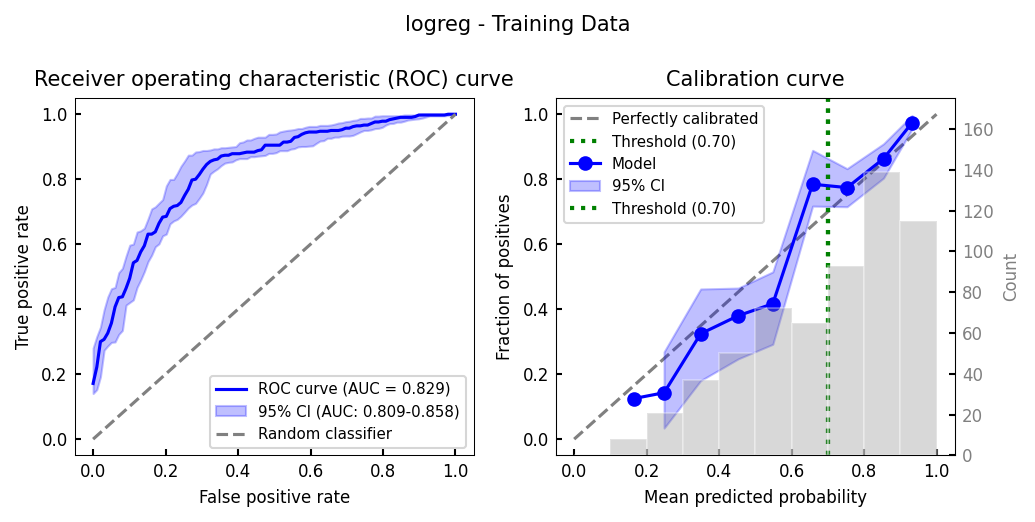

Evaluating on test set...



---- Model Performance Metrics logreg - Test Data ----
Threshold (prevalence) set to: 0.700
AUROC:		0.800 (95% CI: 0.758-0.848) (Area Under the Receiver Operating Characteristic curve)
Accuracy:	0.745 (Proportion of correct predictions)
Precision:	0.868 (Proportion of true positives among positive predictions, aka PPV)
Recall:		0.750 (Proportion of true positives among actual positives, aka sensitivity)
F1 Score:	0.805 (Harmonic mean of precision and recall)
--------------------------------------------


C:\Users\user\PRiSM\prism\metrics.py:820: UserWarning: logreg - Test Data: Skipped confidence intervals for 2 bin(s) due to insufficient samples (threshold: 5). Bin indices: [0 1]. These bins had the following sample counts: [0. 2.].
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:196: UserWarning: logreg - Test Data: 1 point(s) omitted: insufficient samples in probability range(s). Points omitted for probability range(s) [0]: no predictions in these ranges
  warnings.warn(


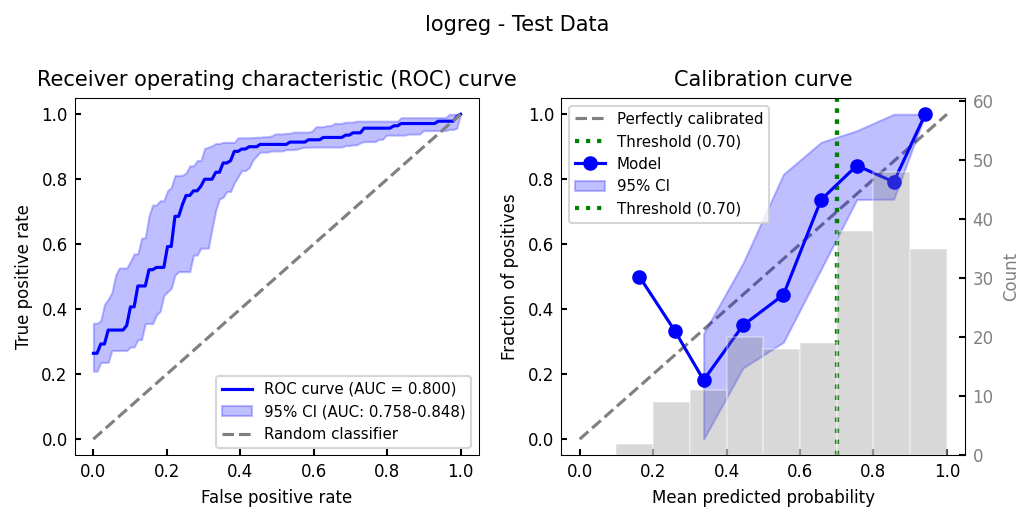


Model Performance Summary:
Training - AUROC: 0.8295, Accuracy: 0.7350
Test     - AUROC: 0.8001, Accuracy: 0.7450


In [11]:
# Evaluate model performance
print("Evaluating model performance...")

# Training set evaluation
print("Evaluating on training set...")
y_pred_train = model.predict_proba(X_train_tensor)
train_metrics = evaluate_model_performance(
    y_train_tensor,
    y_pred_train,
    y_train_tensor,
    title=f"{model_name} - Training Data",
    random_seed=random_seed,
)

# Test set evaluation
print("Evaluating on test set...")
y_pred_test = model.predict_proba(X_test_tensor)
test_metrics = evaluate_model_performance(
    y_test,
    y_pred_test,
    y_train,
    title=f"{model_name} - Test Data",
    random_seed=random_seed,
)

print("\nModel Performance Summary:")
print("=" * 50)
print(f"Training - AUROC: {train_metrics['auroc']:.4f}, Accuracy: {train_metrics['accuracy']:.4f}")
print(f"Test     - AUROC: {test_metrics['auroc']:.4f}, Accuracy: {test_metrics['accuracy']:.4f}")

## Model saving


In [12]:
# Save the model and scaler
print("Saving model and scaler...")

# Create model directory
model_dir = MODELS_DIR / model_identifier
model_dir.mkdir(parents=True, exist_ok=True)

# Generate timestamp for model filename
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_filename = f"{model_identifier}_model_{timestamp}.pt"

# Save model checkpoint
model_path = model_dir / model_filename

# Save the model in PyTorch standard format
torch.save(
    {
        'scaler': scaler,  # Save the scaler with the model
        'model': model,  # Full model for convenience
        'model_state_dict': model.state_dict(),
        'model_class': type(model),
        'hyperparameters': logreg_hyperparameters,
        'feature_names': feature_names,
        'train_metrics': train_metrics,
        'test_metrics': test_metrics,
    },
    model_path
)

print(f"Model saved to: {model_path}")
print(f"Model directory: {model_dir}")

Saving model and scaler...
Model saved to: C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260204_credit-g_full_1\logreg\models\credit-g_logreg\credit-g_logreg_model_20260204_130311.pt
Model directory: C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260204_credit-g_full_1\logreg\models\credit-g_logreg


In [13]:
# Save processed data to PROCESSED_DATA_DIR
# Note: Reference columns have already been dropped during preprocessing
print("\nSaving processed data...")

save_split_datasets(
    train_df=data_train,
    test_df=data_test,
    val_df=data_val,
    base_filename=model_identifier,
    save_dir=PROCESSED_DATA_DIR,
    include_timestamp=True,
    header_comment=f"target: {target_column}, patient IDs: {id_column}. All other features are model inputs, pre-normalization. Reference columns were dropped during preprocessing.",
)

print("Processed data saved successfully.")


Saving processed data...


Saved train dataset (600 samples) to: C:\Users\user\PRiSM\data\processed\credit-g_logreg_20260204_130311_train.csv
Saved test dataset (200 samples) to: C:\Users\user\PRiSM\data\processed\credit-g_logreg_20260204_130311_test.csv
Saved validation dataset (200 samples) to: C:\Users\user\PRiSM\data\processed\credit-g_logreg_20260204_130311_val.csv
Processed data saved successfully.


In [14]:
print(f"\n" + "="*60)
print("MODEL TRAINING COMPLETE")
print("="*60)
print(f"Model identifier: {model_identifier}")
print(f"Model saved to: {model_path}")
print(f"Processed data saved to: {PROCESSED_DATA_DIR}")
print(f"Final test AUROC: {test_metrics['auroc']:.4f}")
print(f"Final test accuracy: {test_metrics['accuracy']:.4f}")
print(f"Features used: {len(feature_names)}")
print(f"Target variable: {target_column}")
print(f"ID variable: {id_column}")


MODEL TRAINING COMPLETE
Model identifier: credit-g_logreg
Model saved to: C:\Users\user\PRiSM\example_notebooks\pipeline_results\20260204_credit-g_full_1\logreg\models\credit-g_logreg\credit-g_logreg_model_20260204_130311.pt
Processed data saved to: C:\Users\user\PRiSM\data\processed
Final test AUROC: 0.8001
Final test accuracy: 0.7450
Features used: 42
Target variable: target
ID variable: trr_id_code
